# ocnBgchem: 3D

3D ocnBgchem data

```{dropdown}  **Branding suffix of datasets**
Datasets with the folloing branding suffix are shown in this page: \
[time]-[vertical]-[horizontal]-[domain]
```
* tavg-ol-hxy-sea
    - tavg: time average
    - ol: ocean levels
    - hxy: horizontal curvlinear grids
    - sea: ocean domain

In [7]:
## Import libraries
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.colors import ListedColormap, BoundaryNorm
import cartopy.feature as cfeature
import cartopy.crs as ccrs
import cmocean
import sys
import os
import glob
from IPython.display import HTML, display

sys.path.append(os.path.dirname(os.getcwd()))
from utils import load_grid_vertex, read_variables, read_compound_names

In [9]:
# load parameters
import yaml
with open('params.yml', 'r') as f:
    param = yaml.safe_load(f)
    cmorout = param['cmorout']
    source_id = param['source_id']
    experiment_id = param['experiment_id']
    variant_label = param['variant_label']
    version = param['version']

In [10]:
# grid label
grid_label = 'g202'         # grid label, e.g., 'gn', 'gr', 'g999'

# data path
data_path = os.path.join(cmorout, source_id, experiment_id, version)

# load grid
grid_file = f"areacello_ti-u-hxy-u_fx_glb_{grid_label}_{source_id}_{experiment_id}_{variant_label}.nc"
if os.path.exists(os.path.join(data_path, grid_file)):
    grid_file = os.path.join(data_path, grid_file)
    with xr.open_dataset(grid_file) as ds:
        parea = ds['areacello']
else:
    grid_file = 'assets/grid.nc'
    with xr.open_dataset(grid_file) as ds:
        parea = ds['parea']
        parea = parea.rename({'y': 'j', 'x': 'i'})

grid_file = f"sftof_ti-u-hxy-u_fx_glb_{grid_label}_{source_id}_{experiment_id}_{variant_label}.nc"
if os.path.exists(os.path.join(data_path, grid_file)):
    grid_file = os.path.join(data_path, grid_file)
    with xr.open_dataset(grid_file) as ds:
        pmask = ds['sftof']
else:
    grid_file = 'assets/grid.nc'
    with xr.open_dataset(grid_file) as ds:
        pmask = ds['pmask']
        pmask = pmask.rename({'y': 'j', 'x': 'i'})

# load methods for plotting and set defaults
methods =read_variables('assets/methods.txt')
#print(methods.keys())

---
```{dropdown}  **List of datasets:** 
List of compound names of datasets that needs to be cmorized. \
Those datasets which are not cmorized have no link.
``

In [11]:
# load compound names
grid_label = 'g???'
coords = ('tavg-ol-hxy-sea')
cnames = read_compound_names('assets/variables.nml')
# examples of compound names:
# cnames = ['ocnBgchem.chl.tavg-ol-hxy-sea.mon.glb', 'ocnBgchem.zooc.tavg-ol-hxy-sea.mon.glb']
for cname in cnames:
    realm = cname.split('.')[0]
    var = cname.split('.')[1]
    coord = cname.split('.')[2]
    freq = cname.split('.')[3]
    region = cname.split('.')[4]
    
    if realm != 'ocnBgchem' or coord not in coords:
        continue
    else:
        file_pattern = f"{var}_{coord}_{freq}_{region}_{grid_label}_{source_id}_{experiment_id}_{variant_label}_*.nc"
        if not glob.glob(os.path.join(data_path, file_pattern)):
            print(cname)
            continue
        else:
            display(HTML(f'<a href="#{cname}">{cname}</a>'))

ocnBgchem.calc.tavg-ol-hxy-sea.mon.glb
ocnBgchem.chl.tavg-ol-hxy-sea.mon.glb
ocnBgchem.detoc.tavg-ol-hxy-sea.mon.glb
ocnBgchem.dfe.tavg-ol-hxy-sea.mon.glb
ocnBgchem.dissic.tavg-ol-hxy-sea.mon.glb
ocnBgchem.dissoc.tavg-ol-hxy-sea.mon.glb
ocnBgchem.nh4.tavg-ol-hxy-sea.mon.glb
ocnBgchem.no3.tavg-ol-hxy-sea.mon.glb
ocnBgchem.o2.tavg-ol-hxy-sea.mon.glb
ocnBgchem.o2sat.tavg-ol-hxy-sea.mon.glb
ocnBgchem.ph.tavg-ol-hxy-sea.mon.glb
ocnBgchem.phyc.tavg-ol-hxy-sea.mon.glb
ocnBgchem.po4.tavg-ol-hxy-sea.mon.glb
ocnBgchem.pp.tavg-ol-hxy-sea.mon.glb
ocnBgchem.si.tavg-ol-hxy-sea.mon.glb
ocnBgchem.talk.tavg-ol-hxy-sea.mon.glb
ocnBgchem.zooc.tavg-ol-hxy-sea.mon.glb


---
```{dropdown}  **Dataset validated:**
Each validated dataset has some text information and some plots (2D and/or 1D)
```

ocnBgchem.chl.tavg-ol-hxy-sea.mon.glb
long name: Mass Concentration of Total Phytoplankton Expressed as Chlorophyll in Sea Water (kg m-3)
vertical aggregation method for 3D->2D plot: mean
timeseries aggregation method for 3D->1D plot: mean
original_name: phyclvl -> chl
history: chl = phyclvl*122*12/60/1000


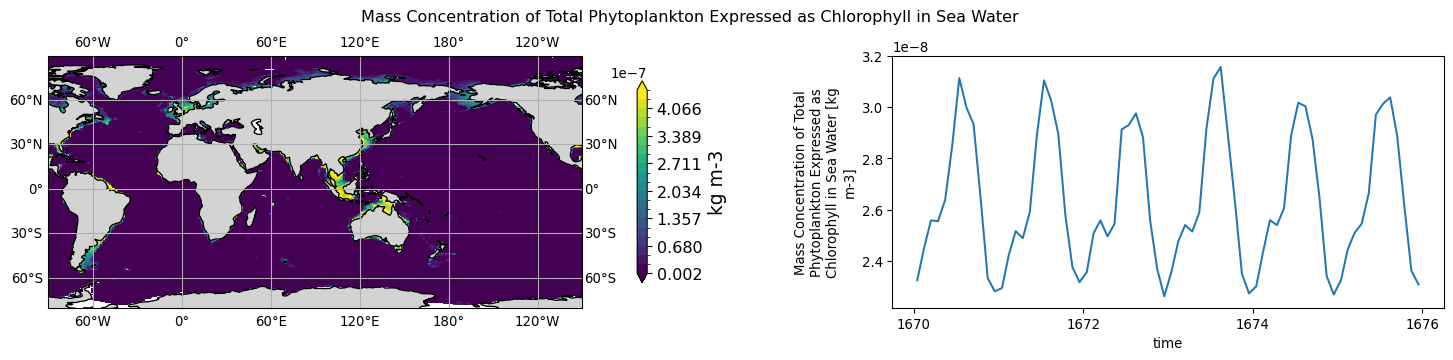

In [15]:
from xarray.coders import CFDatetimeCoder

# loop through compound names and plot
for cname in cnames:
    mth_vert = 'mean'
    mth_ts = 'mean'
    mth_cmap = 'mpl.colormaps["viridis"]'
    if cname not in methods.keys():
        print(f"{cname} not found in methods.txt, using default methods for plotting.")
    else:
        if methods[cname] is not None:
            if 'vertical' in methods[cname].keys():
                mth_vert = methods[cname]['vertical']

            if 'timeseries' in methods[cname].keys():
                mth_ts = methods[cname]['timeseries']

            if 'cmap' in methods[cname].keys():
                mth_cmap = methods[cname]['cmap']

    realm = cname.split('.')[0]
    var = cname.split('.')[1]
    coord = cname.split('.')[2]
    freq = cname.split('.')[3]
    region = cname.split('.')[4]

    if realm != 'ocnBgchem' or coord not in coords:
        continue

    file_pattern = f"{var}_{coord}_{freq}_{region}_{grid_label}_{source_id}_{experiment_id}_{variant_label}_*.nc"

    data_files = sorted(glob.glob(os.path.join(data_path, file_pattern)))
    if data_files:
        with xr.open_mfdataset(data_files, decode_times=CFDatetimeCoder(use_cftime=True)) as ds:
            if var in ds:
                data = ds[var]
                lat = ds['latitude']
                lon = ds['longitude']
                lev_bnds = ds['lev_bnds']
                thk = lev_bnds.diff(dim='bnds').squeeze()
                thk = thk/thk.sum(dim='lev')
            else:
                continue
    else:
        continue

    # remove the las row of grid info if the data has not the last row
    if data.sizes['j'] == 384:
        parea = parea.isel(j=slice(0, 384))
        pmask = pmask.isel(j=slice(0, 384))

    if 'lev' not in data.dims:
        print(f"{cname} does not have vertical dimension 'lev' , skipping vertical aggregation.")
        continue
   
    if mth_vert == 'mean':
        data2d = data.weighted(thk).mean(dim='lev',keep_attrs=True).where(pmask == 1)
    elif mth_vert == 'sum':
        data2d = data.weighted(thk).sum(dim='lev',keep_attrs=True).where(pmask == 1)
    else:
        raise ValueError(f'Unsupported vertical aggregation method: {mth_vert}')

    # remove the las row of grid info if the data has not the last row
    if data2d.sizes['j'] == 384:
        parea = parea.isel(j=slice(0, 384))
        pmask = pmask.isel(j=slice(0, 384))
        
    display(HTML(f'<div id="{cname}"></div>'))
    print(f'\033[1m{cname}\033[0m')
    print(f'long name: {data2d.long_name} ({data2d.units})')
    print(f'vertical aggregation method for 3D->2D plot: {mth_vert}')
    print(f'timeseries aggregation method for 3D->1D plot: {mth_ts}')
    print(f'original_name: {data2d.attrs["original_name"]} -> {var}')
    if 'history' in data2d.attrs:
        print(f'history: {data2d.attrs["history"]}')
    if 'comment' in data2d.attrs:
        print(f'comment: {data2d.attrs["comment"]}')

    #ax1 = fig.add_subplot(1, 2, 1, projection=proj)
    #fig, (ax1, ax2) = plt.subplots( nrows=1, ncols=2, figsize=(12, 5), gridspec_kw={'width_ratios': [2, 1]}, subplot_kw={'projection': proj})

    fig = plt.figure(figsize=(16, 3), dpi=96)
    gs = fig.add_gridspec(nrows=1, ncols=2, width_ratios=[2, 1]) 
    proj = ccrs.PlateCarree(central_longitude=90.0)

    # plot 2D map
    ax1 = fig.add_subplot(gs[0], projection=proj)
    # rescale
    vmin, vmax = data2d.quantile([0.01, 0.99], dim=None).values
    if mth_cmap == 'cmocean.cm.balance':
        vmax = max(abs(vmin),abs(vmax))
        vmin = -vmax
    # Define the discrete levels (boundaries) and the corresponding colors
    levels = np.linspace(vmin, vmax, 21)
    n_levels = 20
    colors = eval(mth_cmap)(np.linspace(0,1,n_levels))
    cmap = ListedColormap(colors)

    # Create a BoundaryNorm to map data to discrete color indices
    norm = BoundaryNorm(levels, ncolors=len(cmap.colors), clip=False)

    if vmin == vmax:
        pm = ax1.pcolormesh(lon, lat, data2d.mean(dim='time'), cmap=cmap,
                            transform=ccrs.PlateCarree(), shading='auto', rasterized=True)
    else:
        pm = ax1.pcolormesh(lon, lat, data2d.mean(dim='time'), cmap=cmap, norm=norm,
                            transform=ccrs.PlateCarree(), shading='auto', rasterized=True)
    # Add map features
    #ax.stock_img()
    ax1.add_feature(cfeature.LAND, facecolor='lightgray')

    gl = ax1.gridlines(ylocs=range(-90, 90, 30), draw_labels=True)
    gl.ylocator = mpl.ticker.FixedLocator(range(-90,90,30))

    # Add colorbar
    cb = plt.colorbar(pm, ax=ax1, fraction=0.4, shrink=0.8, label='[yr]', extend='both')
    cb.set_label(label=data.units, size=14)
    cb.ax.tick_params(labelsize=12)
    plt.tight_layout()
        
    #fig, ax = plot_map2d(lon, lat, data2d.mean(dim='time'), proj='PlateCarree', norm=None, cmap=eval(mth_cmap))
    ax1.coastlines(resolution='110m')
    ax1.add_feature(cfeature.LAND, facecolor='lightgray')
    plt.suptitle(data2d.long_name, y=1.1)

    # plot 1D timeseries
    if mth_ts == 'mean':
        data1d = (data2d*parea).mean(dim=['j', 'i'], keep_attrs=True) / \
                 parea.mean(dim=['j', 'i'])
    elif mth_ts == 'sum':
        data1d = (data2d*parea).sum(dim=['j', 'i'], keep_attrs=True) / \
                 parea.sum(dim=['j', 'i'])
    else:
        raise ValueError(f'Unsupported timeseries method: {mth_ts}')
   
    data1d.attrs = data2d.attrs.copy()

    ax2 = fig.add_subplot(gs[1])
    if data1d.sizes["time"] < 2:
        ax2.text(0.1, 0.8, (f"global {mth_ts} value: {data1d.values[0]} {data1d.units}"))
        ax2.text(0.1, 0.6, ("less than 2 time steps."))
        ax2.text(0.1, 0.4, ("skipping timeseries plot."))
    else:
        data1d.plot(ax=ax2)

    plt.show()

    del data, data2d, data1d
    del ax1, ax2, pm, cb, gl, fig